# Waterfall (Revenue Decomposition)

## Исходные данные для построения

- датафрейм

In [10]:
all_transitions = pd.read_csv('all_transitions.csv')
all_transitions.head(3)

,card,Lifecycle_Stage_from,Monetary_from,Lifecycle_Stage_to,Monetary_to,Revenue_Change,Period
0,2000200195023,Loyal,18068.0,Loyal,15067.0,-3001.0,2021-12-31 -> 2022-01-31
1,2000200193494,At Risk,747.0,At Risk,0.0,-747.0,2021-12-31 -> 2022-01-31
2,2000200199106,Loyal,19535.0,Loyal,19535.0,0.0,2021-12-31 -> 2022-01-31


## Код для построения

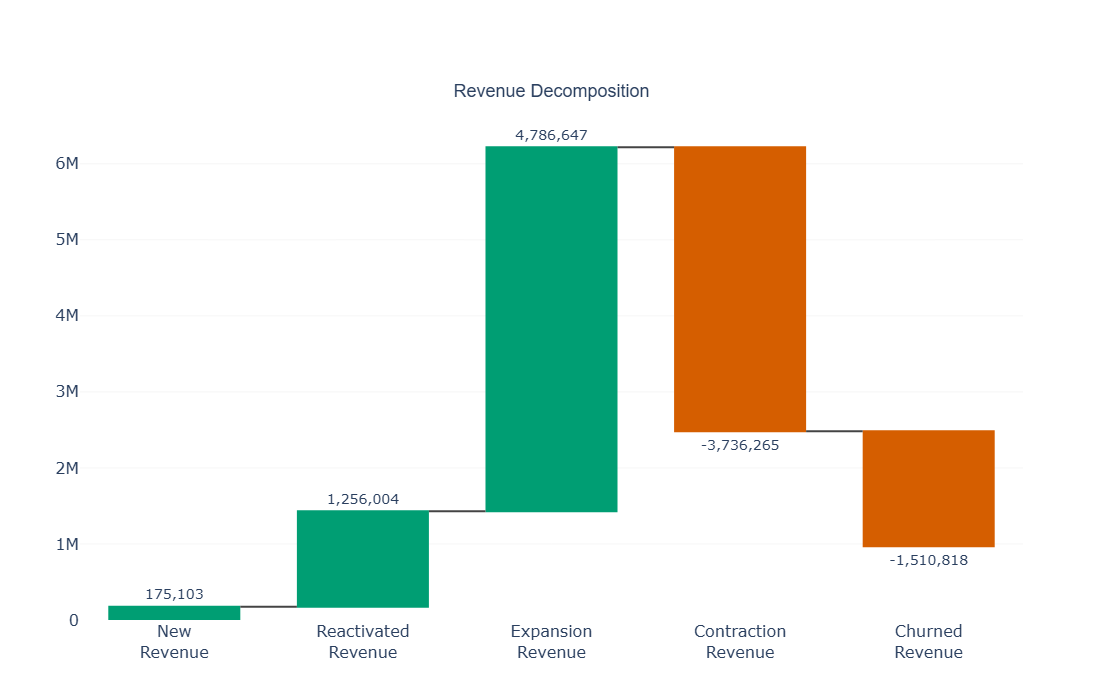

In [8]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import numpy as np
import seaborn as sns
import plotly.graph_objects as go
import matplotlib.pyplot as plt

# =====================================================
# The meaning of colors
# =====================================================

POSITIVE = '#009E73'
NEGATIVE = '#D55E00'

# =====================================================
# LOAD DATA
# =====================================================

all_transitions = pd.read_csv('all_transitions.csv')

# =====================================================
# MASKS
# =====================================================

new_mask = (
    all_transitions['Lifecycle_Stage_to'] == 'New'
)

reactivation_mask = (
    (
        all_transitions['Lifecycle_Stage_from']
        .isin(['At Risk', 'Churn'])
    )
    &
    (
        all_transitions['Lifecycle_Stage_to']
        .isin(['Active', 'Loyal'])
    )
)

churn_mask = (
    all_transitions['Lifecycle_Stage_to'] == 'Churn'
)

retained_mask = (
    (~new_mask)
    &
    (~reactivation_mask)
    &
    (~churn_mask)
)

# =====================================================
# REVENUE ATTRIBUTION
# =====================================================

new_revenue = all_transitions[
    new_mask
]['Monetary_to'].sum()

reactivated_revenue = all_transitions[
    reactivation_mask
]['Monetary_to'].sum()

retained = all_transitions[
    retained_mask
].copy()

contraction_revenue = abs(

    retained[
        retained['Revenue_Change'] < 0
    ]['Revenue_Change'].sum()

)

churned_revenue = all_transitions[
    churn_mask
]['Monetary_from'].sum()

expansion_revenue = retained[
    retained['Revenue_Change'] > 0
]['Revenue_Change'].sum()

# ============================================
# COMPONENTS
# ============================================

components = {
    'New<br>Revenue': new_revenue,
    'Reactivated<br>Revenue': reactivated_revenue,
    'Expansion<br>Revenue': expansion_revenue,
    'Contraction<br>Revenue': -contraction_revenue,
    'Churned<br>Revenue': -churned_revenue
}

labels = list(components.keys())
values = list(components.values())

# ============================================
# WATERFALL
# ============================================

# Создаем объект Figure (фигуру) с одним графиком типа Waterfall
fig = go.Figure(go.Waterfall(

    name='Revenue',  # Имя серии данных (отображается в легенде)

    orientation='v', # Ориентация графика: 'v' = вертикальная (столбцы), 'h' = горизонтальная

    measure=[  # measure — определяет, как каждый столбец строится относительно других:
        'relative', # Здесь все столбцы относительные (каждый следующий от предыдущего)
        'relative',
        'relative',
        'relative',
        'relative'
    ],
    # increasing — настройка для положительных столбцов (рост)
    # marker.color — цвет заливки столбцов с положительным значением
    increasing = {"marker": {"color": POSITIVE}}, # Green for positive deltas
    # decreasing — настройка для отрицательных столбцов (падение)
    decreasing = {"marker": {"color": NEGATIVE}}, # Orange for negative deltas
    # totals — настройка для итоговых столбцов (если есть 'total' в measure)
    totals     = {"marker": {"color": "#4C72B0"}},
    
    x=labels, # x — подписи под столбцами (категории) ['New<br>Revenue', 'Reactivated<br>Revenue', ...]

    y=values, # y — значения столбцов (высота/глубина) [175103, 1256004, 4786647, -3736265, -1510818]

    text=[ # text — текст над каждым столбцом (подписи значений)
        f"{v:,.0f}" # форматируем с разделителями тысяч (без десятичных)
        for v in values # для каждого значения из списка
    ],
    textposition='outside' # textposition — положение текста относительно столбца: 'outside' — над столбцом (снаружи)
))

# ============================================
# НАСТРОЙКА МАКЕТА (LAYOUT) ГРАФИКА
# ============================================

fig.update_layout( # update_layout() — применяет общие настройки к фигуре
    title=dict( # title — настройки заголовка
        text="Revenue Decomposition", # текст заголовка
        font=dict(size=18, family="Arial"), # размер и шрифт
        y=0.88, # вертикальная позиция (0=низ, 1=верх)                    # ← опускаем ниже (0 = низ, 1 = верх)
        x=0.5, # горизонтальная позиция (0=лево, 0.5=центр)
        xanchor='center', # привязка по горизонтали: центр
        yanchor='top'  # привязка по вертикали: верх
    ),
    waterfallgap=0.3, # waterfallgap — расстояние между столбцами (0.3 = 30% от ширины)

    xaxis=dict(tickfont=dict( # xaxis — настройки оси X (горизонтальной)
        size=16)), # размер шрифта подписей на оси X
    
    yaxis=dict(tickfont=dict( # yaxis — настройки оси Y (вертикальной)
        size=16), # размер шрифта подписей на оси Y
        gridcolor='#EDEDED', # цвет линий сетки (светло-серый)
        gridwidth=0.5,  # толщина линий сетки
        showgrid=True, # показывать сетку по оси Y
        zeroline=False  # НЕ показывать линию на нуле     
              ),
        
    height=700, # height — высота фигуры в пикселях
    width=1100, # width — ширина фигуры в пикселях

    plot_bgcolor="white", # plot_bgcolor — цвет фона области с графиком
    paper_bgcolor="white", # paper_bgcolor — цвет фона всей фигуры (включая отступы)
)

# ============================================
# НАСТРОЙКА ТЕКСТА НА СТОЛБЦАХ
# ============================================

fig.update_traces( # update_traces() — применяет настройки к элементам данных (графикам)
    textfont=dict( # textfont — настройки шрифта для текста на столбцах
        size=14 # размер шрифта подписей значений
    )
)

# ============================================
# СОХРАНЕНИЕ И ОТОБРАЖЕНИЕ
# ============================================

# write_image() — сохраняет фигуру в изображение (PNG)
# Для работы требуется библиотека kaleido
# Раскомментируйте нужную строку для сохранения

# Вариант 1: Сохранить с настройками по умолчанию
# fig.write_image("revenue_exposure_analysis.png")

# Вариант 2: Сохранить с указанием размера
# fig.write_image("revenue_exposure_analysis.png", width=1100, height=700)

# Вариант 3: Сохранить с высоким разрешением (scale=2 = 2x) С высоким разрешением (300 dpi), scale=2 = 2x разрешение
# fig.write_image("revenue_decomposition.png", width=1100, height=700, scale=2)

# write_html() — сохраняет в HTML (интерактивный график)
# fig.write_html("revenue_decomposition_waterfall.html")

# show() — отображает график в браузере / Jupyter Notebook

fig.show()